# Laboratorio 10 - Deep Learning

- Juan Diego Solís Martínez - 23720
- Victor Manuel Pérez Chávez - 23731
- Diego Oswaldo Flores Rivas - 23714

## Task 2

In [1]:
# !pip install shap
import time
from itertools import combinations
from math import factorial
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import warnings
warnings.filterwarnings("ignore")
from scipy.stats import spearmanr
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.inspection import permutation_importance

SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 160)
print("Semilla aleatoria:", SEED)

Semilla aleatoria: 42


### Task 2.1

Se carga German Credit, se codifican la clase (good = 1, bad = 0) y las categóricas con un codificador ordinal, se divide 80/20 estratificado y se entrena el gradient boosting con los parámetros de la tabla.

In [2]:
datos = fetch_openml("credit-g", version=1, as_frame=True)
X_raw = datos.data.copy()
y = (datos.target == "good").astype(int)

cat_cols = X_raw.select_dtypes(include=["category", "object"]).columns.tolist()
num_cols = [c for c in X_raw.columns if c not in cat_cols]
print(f"{X_raw.shape[0]} solicitudes, {len(num_cols)} numéricas y {len(cat_cols)} categóricas")

# Codificador ordinal: los códigos son arbitrarios y se tratan como numéricos
# (limitación: imponen un orden y distancias entre categorías que no existen)
enc = OrdinalEncoder()
X = X_raw.copy()
X[cat_cols] = enc.fit_transform(X_raw[cat_cols])
X = X.astype(float)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

modelo = GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=SEED)
modelo.fit(X_train, y_train)

p_test = modelo.predict_proba(X_test)[:, 1]
print(f"Exactitud en prueba: {accuracy_score(y_test, (p_test >= 0.5).astype(int)):.4f}")
print(f"AUC en prueba:       {roc_auc_score(y_test, p_test):.4f}")

1000 solicitudes, 7 numéricas y 13 categóricas


Exactitud en prueba: 0.7750
AUC en prueba:       0.7650


### Task 2.2

Se calculan los valores SHAP del conjunto de prueba con TreeExplainer intervencional en log-odds y un fondo de 100 instancias de entrenamiento, y se verifican eficiencia, valor base e importancias.

In [3]:
rng = np.random.default_rng(SEED)
fondo = X_train.iloc[rng.choice(len(X_train), 100, replace=False)]

explicador = shap.TreeExplainer(modelo, data=fondo, feature_perturbation="interventional", model_output="raw")
sv = explicador(X_test)
phi = sv.values                                   # (200, 20)
phi0 = float(np.ravel(explicador.expected_value)[0])
f_test = modelo.decision_function(X_test)         # salida en log-odds
print("Forma de los valores SHAP:", phi.shape)

Forma de los valores SHAP: (200, 20)


**a.** Eficiencia: $\phi_0 + \sum_j \phi_j = f(x)$ en log-odds.

In [4]:
# a. phi_0 + sum_j phi_j = f(x)
err_ef = np.abs(phi0 + phi.sum(axis=1) - f_test)
print(f"Error absoluto máximo de eficiencia: {err_ef.max():.3e}")

Error absoluto máximo de eficiencia: 9.722e-08


**b.** El valor base debe ser el promedio de $f$ sobre el fondo.

In [5]:
# b. phi_0 = E_fondo[f(x)]
f_fondo = modelo.decision_function(fondo).mean()
print(f"Valor base phi_0:           {phi0:.6f}")
print(f"Promedio de f en el fondo:  {f_fondo:.6f}")
print(f"Diferencia absoluta:        {abs(phi0 - f_fondo):.3e}")

Valor base phi_0:           1.430742
Promedio de f en el fondo:  1.430742
Diferencia absoluta:        0.000e+00


**c.** Importancia global $I_j$ contra importancia por permutación (AUC, 10 repeticiones).

In [6]:
# c. I_j = (1/N) sum_n |phi_j^(n)|
I = np.abs(phi).mean(axis=0)
perm = permutation_importance(modelo, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=SEED)

imp = pd.DataFrame({"I_j (SHAP)": I, "Permutación (AUC)": perm.importances_mean,
                    "Perm. std": perm.importances_std}, index=X.columns)
imp["Rank SHAP"] = imp["I_j (SHAP)"].rank(ascending=False).astype(int)
imp["Rank perm."] = imp["Permutación (AUC)"].rank(ascending=False).astype(int)

print("Top 5 por I_j:")
print(imp.sort_values("I_j (SHAP)", ascending=False).head(5)[["I_j (SHAP)"]].round(4))
print("\nTop 5 por permutación:")
print(imp.sort_values("Permutación (AUC)", ascending=False).head(5)[["Permutación (AUC)", "Perm. std"]].round(4))
rho, pval = spearmanr(imp["I_j (SHAP)"], imp["Permutación (AUC)"])
print(f"\nSpearman entre los dos rankings completos: {rho:.4f} (p = {pval:.3g})")
print("\nTabla completa:")
print(imp.sort_values("Rank SHAP").round(4).to_string())

Top 5 por I_j:
                 I_j (SHAP)
checking_status      0.7603
purpose              0.5117
credit_amount        0.4902
duration             0.3917
savings_status       0.2963

Top 5 por permutación:
                 Permutación (AUC)  Perm. std
checking_status             0.1190     0.0301
credit_amount               0.0762     0.0136
duration                    0.0579     0.0119
credit_history              0.0396     0.0112
savings_status              0.0262     0.0112

Spearman entre los dos rankings completos: 0.6496 (p = 0.00194)

Tabla completa:
                        I_j (SHAP)  Permutación (AUC)  Perm. std  Rank SHAP  Rank perm.
checking_status             0.7603             0.1190     0.0301          1           1
purpose                     0.5117             0.0037     0.0107          2          12
credit_amount               0.4902             0.0762     0.0136          3           2
duration                    0.3917             0.0579     0.0119          4        

**d.** Cascadas de un cliente con $p(\text{good}) > 0.8$ y otro con $p(\text{good}) < 0.2$, y beeswarm global.

Aprobado: posición 50 en prueba (índice original 175), p(good) = 0.9994, f(x) = 7.4990
   purpose                   valor = used car                     phi = +1.4633
   age                       valor = 53                           phi = +1.1045
   checking_status           valor = no checking                  phi = +1.0069


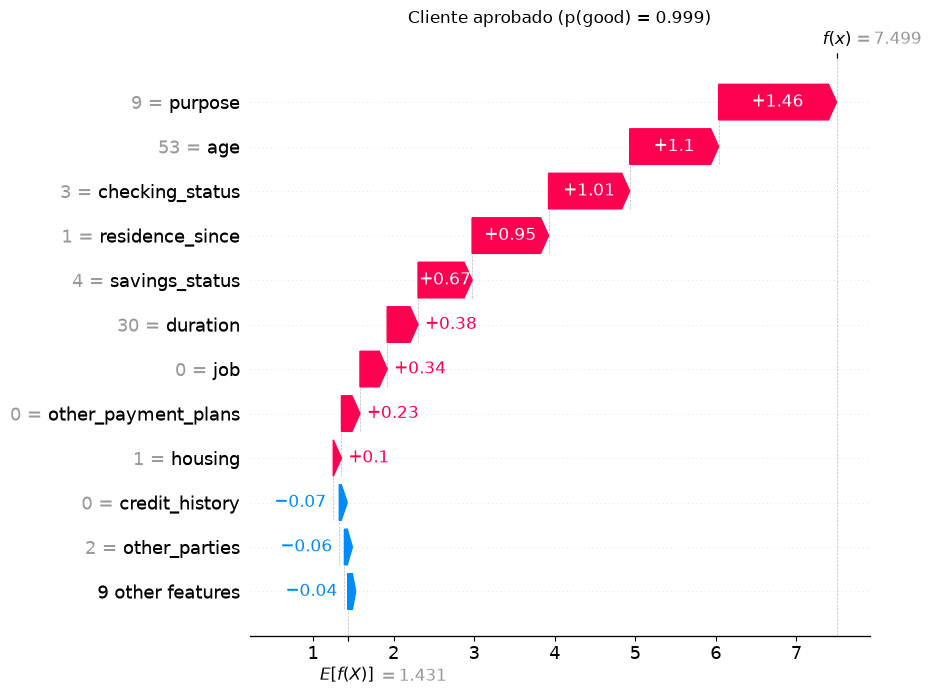

Rechazado: posición 76 en prueba (índice original 721), p(good) = 0.0517, f(x) = -2.9084
   credit_history            valor = all paid                     phi = -1.3162
   savings_status            valor = >=1000                       phi = +0.9721
   credit_amount             valor = 433                          phi = -0.9654


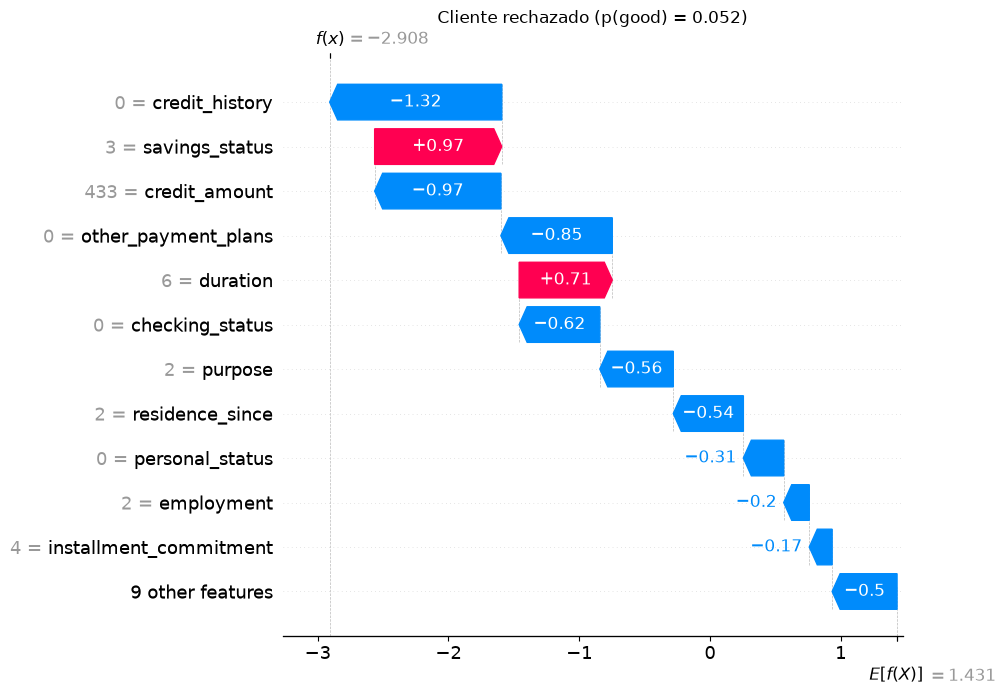

In [7]:
# d. Cliente aprobado (máxima p) y rechazado (mínima p) del conjunto de prueba
i_bueno = int(np.argmax(p_test))
i_malo = int(np.argmin(p_test))
assert p_test[i_bueno] > 0.8 and p_test[i_malo] < 0.2

for nombre, i in [("Aprobado", i_bueno), ("Rechazado", i_malo)]:
    print(f"{nombre}: posición {i} en prueba (índice original {X_test.index[i]}), "
          f"p(good) = {p_test[i]:.4f}, f(x) = {f_test[i]:.4f}")
    top3 = np.argsort(-np.abs(phi[i]))[:3]
    for j in top3:
        col = X.columns[j]
        print(f"   {col:25s} valor = {X_raw.loc[X_test.index[i], col]!s:28s} phi = {phi[i, j]:+.4f}")
    plt.figure()
    shap.plots.waterfall(sv[i], max_display=12, show=False)
    plt.title(f"Cliente {nombre.lower()} (p(good) = {p_test[i]:.3f})")
    plt.show()

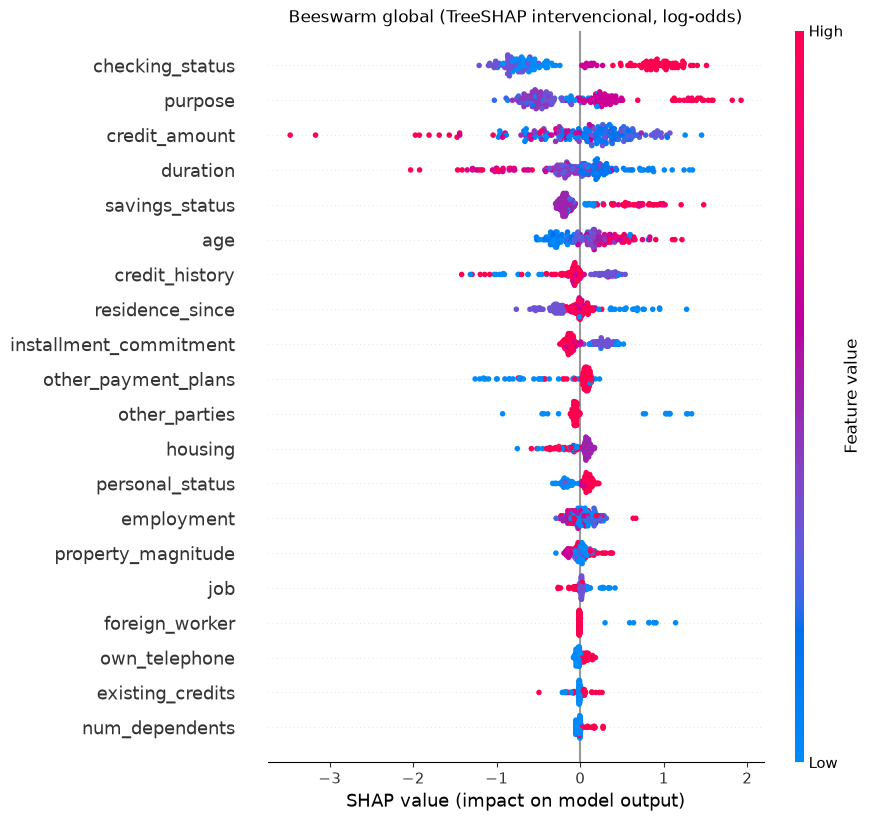

In [8]:
shap.plots.beeswarm(sv, max_display=20, show=False)
plt.title("Beeswarm global (TreeSHAP intervencional, log-odds)")
plt.show()

### Task 2.3

Se duplica con ruido la variable numérica de mayor $I_j$, se reentrena con 21 variables y se comparan los SHAP intervencional y dependiente de la trayectoria.

In [9]:
var = max(num_cols, key=lambda c: I[X.columns.get_loc(c)])
print("Variable numérica de mayor I_j:", var, f"(I_j = {I[X.columns.get_loc(var)]:.4f})")

# x_dup = x + 0.05 sigma_x eps
rng = np.random.default_rng(SEED)
X_dup = X.copy()
X_dup[var + "_copia"] = X[var] + 0.05 * X[var].std() * rng.standard_normal(len(X))
Xd_train, Xd_test = X_dup.loc[X_train.index], X_dup.loc[X_test.index]
print(f"Correlación original-copia: {np.corrcoef(X_dup[var], X_dup[var + '_copia'])[0, 1]:.4f}")

modelo_dup = GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=SEED).fit(Xd_train, y_train)

exp_int = shap.TreeExplainer(modelo_dup, data=Xd_train.loc[fondo.index], feature_perturbation="interventional", model_output="raw")
exp_tpd = shap.TreeExplainer(modelo_dup, feature_perturbation="tree_path_dependent", model_output="raw")
j_o, j_c = Xd_test.columns.get_loc(var), Xd_test.columns.get_loc(var + "_copia")

filas = {}
for nombre, ex in [("Intervencional", exp_int), ("Tree path dependent", exp_tpd)]:
    ph = ex.shap_values(Xd_test)
    filas[nombre] = [np.abs(ph[:, j_o]).mean(), np.abs(ph[:, j_c]).mean(), np.abs(ph[:, j_o] + ph[:, j_c]).mean()]
tabla_dup = pd.DataFrame(filas, index=["mean |phi_orig|", "mean |phi_copia|", "mean |phi_orig + phi_copia|"]).T
tabla_dup["I_j sin copia"] = I[X.columns.get_loc(var)]
print(tabla_dup.round(4).to_string())

Variable numérica de mayor I_j: credit_amount (I_j = 0.4902)
Correlación original-copia: 0.9988


                     mean |phi_orig|  mean |phi_copia|  mean |phi_orig + phi_copia|  I_j sin copia
Intervencional                0.5180            0.4285                       0.5460         0.4902
Tree path dependent           0.3814            0.3630                       0.5308         0.4902


### Task 2.4

Se compara KernelSHAP (2 000 muestras por instancia) con TreeSHAP intervencional en 10 instancias de prueba, para fondos de 10, 50 y 100 instancias, midiendo error y tiempo.

In [10]:
X10 = X_test.iloc[:10]
f_logodds = lambda Z: modelo.decision_function(pd.DataFrame(Z, columns=X.columns))  # salida en log-odds

res_kernel = []
for nb in [10, 50, 100]:
    fondo_b = fondo.iloc[:nb]   # subconjunto del fondo de 100 del Task 2.2
    # a. KernelSHAP
    t0 = time.perf_counter()
    ke = shap.KernelExplainer(f_logodds, fondo_b.values)
    phi_k = ke.shap_values(X10.values, nsamples=2000, l1_reg=False, silent=True)  # sin selección de variables
    t_k = time.perf_counter() - t0
    # b. TreeSHAP intervencional con el mismo fondo
    t0 = time.perf_counter()
    phi_t = shap.TreeExplainer(modelo, data=fondo_b, feature_perturbation="interventional", model_output="raw").shap_values(X10)
    t_t = time.perf_counter() - t0
    res_kernel.append([nb, np.abs(phi_k - phi_t).mean(), t_k, t_k / len(X10), t_t])

tabla_kernel = pd.DataFrame(res_kernel, columns=["Fondo", "MAE vs TreeSHAP", "Tiempo Kernel (s)",
                                                 "Kernel por instancia (s)", "Tiempo Tree (s)"])
print(tabla_kernel.round(5).to_string(index=False))

 Fondo  MAE vs TreeSHAP  Tiempo Kernel (s)  Kernel por instancia (s)  Tiempo Tree (s)
    10          0.00246            0.58231                   0.05823          0.00753
    50          0.00437            2.08445                   0.20844          0.01384
   100          0.00409            3.92773                   0.39277          0.02367


### Task 2.5

Se entrena un modelo con seis variables numéricas y se calculan los Shapley exactos con la fórmula de clase sobre las 64 coaliciones, comparando con TreeSHAP intervencional.

In [11]:
num6 = ["duration", "credit_amount", "installment_commitment", "residence_since", "age", "existing_credits"]
modelo6 = GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=SEED).fit(X_train[num6], y_train)

rng = np.random.default_rng(SEED)
fondo6 = X_train[num6].iloc[rng.choice(len(X_train), 50, replace=False)]
X5 = X_test[num6].iloc[:5]
M = len(num6)

# a. v(S) = promedio sobre el fondo de f con x_S fijo y el resto tomado del fondo
def v(S, x):
    Z = fondo6.values.copy()
    Z[:, list(S)] = x[list(S)]
    return modelo6.decision_function(pd.DataFrame(Z, columns=num6)).mean()

coaliciones = [S for r in range(M + 1) for S in combinations(range(M), r)]
print("Número de coaliciones:", len(coaliciones))

# b. phi_i = sum_{S sin i} |S|!(M-|S|-1)!/M! [v(S U {i}) - v(S)]
phi_ex = np.zeros((len(X5), M))
efic = []
for n, x in enumerate(X5.values):
    vals = {S: v(S, x) for S in coaliciones}
    for i in range(M):
        for S in coaliciones:
            if i in S:
                continue
            peso = factorial(len(S)) * factorial(M - len(S) - 1) / factorial(M)
            phi_ex[n, i] += peso * (vals[tuple(sorted(S + (i,)))] - vals[S])
    efic.append(abs(phi_ex[n].sum() - (vals[tuple(range(M))] - vals[()])))

# c. Comparación con TreeSHAP intervencional (mismo fondo)
phi_tree6 = shap.TreeExplainer(modelo6, data=fondo6, feature_perturbation="interventional", model_output="raw").shap_values(X5)
print(f"Error absoluto máximo vs TreeSHAP: {np.abs(phi_ex - phi_tree6).max():.3e}")
print(f"Error máximo de eficiencia |sum phi - (v(N) - v(vacío))|: {max(efic):.3e}")
print("\nphi exactos (fórmula propia):")
print(pd.DataFrame(phi_ex, columns=num6, index=X5.index).round(4).to_string())

Número de coaliciones: 64


Error absoluto máximo vs TreeSHAP: 2.431e-08
Error máximo de eficiencia |sum phi - (v(N) - v(vacío))|: 3.331e-16

phi exactos (fórmula propia):
     duration  credit_amount  installment_commitment  residence_since     age  existing_credits
977   -0.4652         0.3353                 -0.0531          -0.1108  0.3497            0.1798
735   -1.1717         0.0933                 -0.0414          -0.1200 -0.3254           -0.0749
615    0.3206        -1.4417                  0.0311           0.0155  0.5182           -0.0785
413    0.5520         0.6827                 -0.0529          -0.1470  0.5080           -0.1110
563    0.6749        -1.5028                  0.0285           0.0134  0.9341           -0.0839


### Task 2.6

Esta sección es de análisis: aquí solo se calculan los números que se usan en las respuestas del documento.

**a.** Efectos individuales en probabilidad del cliente rechazado.

In [12]:
sig = lambda z: 1 / (1 + np.exp(-z))
p_x, p_base = sig(f_test[i_malo]), sig(phi0)
efecto = sig(phi0 + phi[i_malo]) - p_base   # sigma(phi_0 + phi_j) - sigma(phi_0)
print(f"p(x) = sigma(f(x)) = {p_x:.4f},  sigma(phi_0) = {p_base:.4f}")
print(f"Suma de efectos individuales: {efecto.sum():+.4f}")
print(f"p(x) - sigma(phi_0):          {p_x - p_base:+.4f}")
print(f"Suma de phi en log-odds: {phi[i_malo].sum():+.4f}  vs  f(x) - phi_0: {f_test[i_malo] - phi0:+.4f}")
print(pd.DataFrame({"phi (log-odds)": phi[i_malo], "efecto en p": efecto}, index=X.columns)
      .sort_values("phi (log-odds)").round(4).to_string())

p(x) = sigma(f(x)) = 0.0517,  sigma(phi_0) = 0.8070
Suma de efectos individuales: -0.9457
p(x) - sigma(phi_0):          -0.7553
Suma de phi en log-odds: -4.3391  vs  f(x) - phi_0: -4.3391
                        phi (log-odds)  efecto en p
credit_history                 -1.3162      -0.2784
credit_amount                  -0.9654      -0.1927
other_payment_plans            -0.8519      -0.1662
checking_status                -0.6167      -0.1140
purpose                        -0.5619      -0.1025
residence_since                -0.5359      -0.0971
personal_status                -0.3086      -0.0526
employment                     -0.1955      -0.0323
installment_commitment         -0.1748      -0.0287
other_parties                  -0.1138      -0.0183
housing                        -0.0752      -0.0120
age                            -0.0743      -0.0118
existing_credits               -0.0733      -0.0117
property_magnitude             -0.0603      -0.0096
num_dependents                 -

**b.** Variable con mayor diferencia de posición entre rankings y sus correlaciones.

In [13]:
imp["Diferencia"] = (imp["Rank SHAP"] - imp["Rank perm."]).abs()
print(imp.sort_values("Diferencia", ascending=False).head(5)[["I_j (SHAP)", "Permutación (AUC)", "Rank SHAP", "Rank perm.", "Diferencia"]].round(4))
var_b = imp["Diferencia"].idxmax()
print("\nVariable con mayor diferencia:", var_b)
corr = X_train.corr(method="spearman")[var_b].drop(var_b)
print("\nCorrelaciones de Spearman con las demás variables (entrenamiento):")
print(corr.reindex(corr.abs().sort_values(ascending=False).index).round(3).head(8).to_string())

                 I_j (SHAP)  Permutación (AUC)  Rank SHAP  Rank perm.  Diferencia
age                  0.2885            -0.0054          6          20          14
purpose              0.5117             0.0037          2          12          10
foreign_worker       0.0435             0.0056         17          10           7
employment           0.1113             0.0082         14           8           6
residence_since      0.2079             0.0022          8          13           5

Variable con mayor diferencia: age

Correlaciones de Spearman con las demás variables (entrenamiento):
housing            -0.312
employment          0.306
personal_status     0.273
residence_since     0.245
credit_history     -0.200
num_dependents      0.196
own_telephone       0.181
existing_credits    0.137


**d.** Costo de KernelSHAP y del cálculo exacto.

In [14]:
# Escala del tiempo de KernelSHAP con el tamaño del fondo
tabla_kernel["Tiempo / fondo (s)"] = tabla_kernel["Tiempo Kernel (s)"] / tabla_kernel["Fondo"]
print(tabla_kernel[["Fondo", "Tiempo Kernel (s)", "Tiempo / fondo (s)", "MAE vs TreeSHAP"]].round(5).to_string(index=False))

# Tiempo de una predicción sobre 100 instancias (una evaluación de v(S) con fondo de 100)
reps = 200
t0 = time.perf_counter()
for _ in range(reps):
    modelo.decision_function(fondo)
t_pred = (time.perf_counter() - t0) / reps
t_exacto20 = 2**20 * t_pred
t_kernel_inst = tabla_kernel.loc[tabla_kernel["Fondo"] == 100, "Kernel por instancia (s)"].item()
print(f"\nPredicción sobre 100 instancias: {t_pred * 1e3:.3f} ms")
print(f"Shapley exacto, 20 variables (2^20 evaluaciones): {t_exacto20:.1f} s = {t_exacto20 / 60:.1f} min por instancia")
print(f"KernelSHAP (fondo 100) por instancia: {t_kernel_inst:.3f} s  -> exacto es {t_exacto20 / t_kernel_inst:.0f} veces más lento")

anios60 = 2**60 * 1e-6 / (365.25 * 24 * 3600)
print(f"Exacto con 60 variables a 1 microsegundo por evaluación: {anios60:,.0f} años")

 Fondo  Tiempo Kernel (s)  Tiempo / fondo (s)  MAE vs TreeSHAP
    10            0.58231             0.05823          0.00246
    50            2.08445             0.04169          0.00437
   100            3.92773             0.03928          0.00409

Predicción sobre 100 instancias: 0.858 ms
Shapley exacto, 20 variables (2^20 evaluaciones): 899.8 s = 15.0 min por instancia
KernelSHAP (fondo 100) por instancia: 0.393 s  -> exacto es 2291 veces más lento
Exacto con 60 variables a 1 microsegundo por evaluación: 36,534 años
